In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import warnings
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                           roc_auc_score, classification_report, confusion_matrix, roc_curve)
import pickle

warnings.filterwarnings('ignore')
plt.rcParams['font.size'] = 12
plt.rcParams['figure.figsize'] = (10, 6)
PLOTS_DIR = "../static/plots"
os.makedirs(PLOTS_DIR, exist_ok=True)
np.random.seed(42)

Rozmiar zbioru: (88647, 112)
Liczba cech: 111

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bez phisingowe: 58,000 (65.4%)
URL oznaczone jako phisingowe: 30,647 (34.6%)


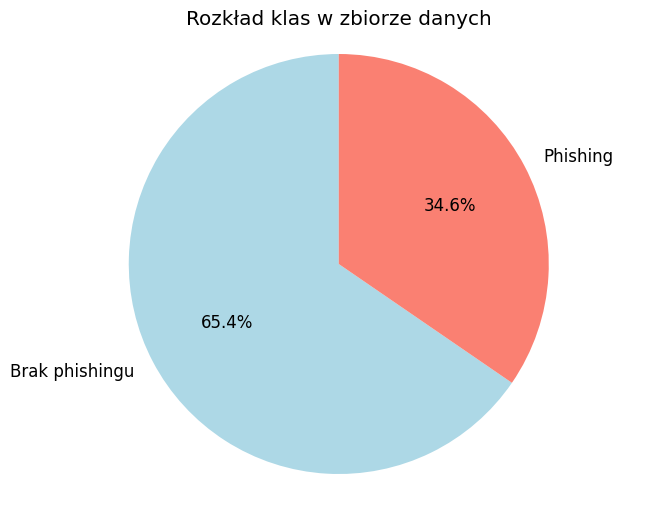


Informacje o zbiorze:
- Łączna liczba próbek: 88,647- Łączna liczba próbek: 88,647
- Liczba cech: 111

- Liczba cech: 111
- Brakujące wartości: 0
- Brakujące wartości: 0
- Duplikaty: 1438

Dostępne cechy: 100
Przykładowe cechy: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url']
- Duplikaty: 1438

Dostępne cechy: 100
Przykładowe cechy: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url']


In [2]:
df = pd.read_csv('../data/dataset_full.csv')

print(f"Rozmiar zbioru: {df.shape}")
print(f"Liczba cech: {len(df.columns)-1}")

print(f"\nPierwsze 5 kolumn: {list(df.columns[:5])}")
print(f"Ostatnie 5 kolumn: {list(df.columns[-5:])}")

label_counts = df['phishing'].value_counts()
print(f"\nRozkład etykiet:")
print(f"URL oznaczone jako bez phisingowe: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
print(f"URL oznaczone jako phisingowe: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")

plt.figure(figsize=(8, 6))
colors = ['lightblue', 'salmon']
labels = ['Brak phishingu', 'Phishing']
plt.pie(label_counts.values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Rozkład klas w zbiorze danych')
plt.axis('equal')
plt.show()

print(f"\nInformacje o zbiorze:")
print(f"- Łączna liczba próbek: {len(df):,}")
print(f"- Liczba cech: {len(df.columns)-1}")
print(f"- Brakujące wartości: {df.isnull().sum().sum()}")
print(f"- Duplikaty: {df.duplicated().sum()}")

feature_columns = [col for col in df.columns if col != 'phishing' and col not in [
    'time_response', 'domain_spf', 'asn_ip', 'time_domain_activation', 
    'time_domain_expiration', 'qty_ip_resolved', 'qty_nameservers', 
    'qty_mx_servers', 'ttl_hostname', 'url_google_index', 'domain_google_index'
]]
print(f"\nDostępne cechy: {len(feature_columns)}")
print(f"Przykładowe cechy: {feature_columns[:10]}")

In [3]:
network_dependent_features = [
    'time_response', 'domain_spf', 'asn_ip', 'time_domain_activation', 
    'time_domain_expiration', 'qty_ip_resolved', 'qty_nameservers', 
    'qty_mx_servers', 'ttl_hostname', 'url_google_index', 'domain_google_index'
]

feature_columns = [col for col in df.columns if col != 'phishing' and col not in network_dependent_features]
X = df[feature_columns]
y = df['phishing']             

print(f"\nTypy danych cech:")
data_types = X.dtypes.value_counts()
for dtype, count in data_types.items():
    print(f"  {dtype}: {count} kolumn")

inf_count = np.isinf(X.select_dtypes(include=[np.number])).sum().sum()
nan_count = X.isnull().sum().sum()

print(f"  Wartości nieskończone: {inf_count}")
print(f"  Wartości brakujące: {nan_count}")

if inf_count > 0:
    print("Wykryto wartości nieskończone - zastępowanie medianą...")
    X = X.replace([np.inf, -np.inf], np.nan)

if X.isnull().sum().sum() > 0:
    print("Wykryto wartości brakujące - zastępowanie medianą...")
    X = X.fillna(X.median())

print(f"\nStatystyki cech przed skalowaniem:")
X_num = X.select_dtypes(include=[np.number])
print(f"  Minimum: {X_num.min().min():.4f}")
print(f"  Maksimum: {X_num.max().max():.4f}")
print(f"  Średnia: {X_num.mean().mean():.4f}")
print(f"  Odchylenie standardowe: {X_num.std().mean():.4f}")


Typy danych cech:
  int64: 100 kolumn
  Wartości nieskończone: 0
  Wartości brakujące: 0
  Wartości nieskończone: 0
  Wartości brakujące: 0

Statystyki cech przed skalowaniem:
  Minimum: -1.0000
  Maksimum: 4165.0000
  Średnia: 0.5481

Statystyki cech przed skalowaniem:
  Minimum: -1.0000
  Maksimum: 4165.0000
  Średnia: 0.5481
  Odchylenie standardowe: 1.7407
  Odchylenie standardowe: 1.7407


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,      
    random_state=42,    
    stratify=y          
)

print(f"Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

print(f"\nRozkład klas w zbiorze uczącym:")
train_counts = y_train.value_counts()
print(f"  Brak phishingu: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
print(f"  Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")

print(f"\nRozkład klas w zbiorze testowym:")
test_counts = y_test.value_counts()
print(f"  Brak phishingu: {test_counts[0]:,} ({test_counts[0]/len(y_test)*100:.1f}%)")
print(f"  Phishing: {test_counts[1]:,} ({test_counts[1]/len(y_test)*100:.1f}%)")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nStatystyki cech po skalowaniu (zbiór uczący):")
print(f"  Średnia: {X_train_scaled.mean():.6f}")
print(f"  Odchylenie standardowe: {X_train_scaled.std():.6f}")
print(f"  Minimum: {X_train_scaled.min():.4f}")
print(f"  Maksimum: {X_train_scaled.max():.4f}")

Zbiór uczący: 70,917 próbek (80.0%)
Zbiór testowy: 17,730 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Brak phishingu: 46,400 (65.4%)
  Phishing: 24,517 (34.6%)

Rozkład klas w zbiorze testowym:
  Brak phishingu: 11,600 (65.4%)
  Phishing: 6,130 (34.6%)

Statystyki cech po skalowaniu (zbiór uczący):
  Średnia: 0.000000
  Odchylenie standardowe: 0.932738
  Minimum: -4.0788
  Maksimum: 266.3006

Statystyki cech po skalowaniu (zbiór uczący):
  Średnia: 0.000000
  Odchylenie standardowe: 0.932738
  Minimum: -4.0788
  Maksimum: 266.3006


In [5]:

param_grids = [
    {
        'name': 'Podstawowe architektury',
        'params': {
            'hidden_layer_sizes': [(50,), (100,), (50, 50)],
            'activation': ['relu', 'tanh'],
            'alpha': [0.0001, 0.001, 0.01],
            'learning_rate': ['constant', 'adaptive']
        }
    },
    {
        'name': 'Rozszerzone konfiguracje',
        'params': {
            'hidden_layer_sizes': [(100,), (100, 50), (100, 100)],
            'activation': ['relu', 'logistic'],
            'alpha': [0.0001, 0.001, 0.01],
            'solver': ['adam', 'lbfgs'],
            'learning_rate': ['constant', 'adaptive']
        }
    },
    {
        'name': 'Zaawansowane sieci',
        'params': {
            'hidden_layer_sizes': [(200,), (100, 100), (200, 100), (150, 100, 50)],
            'activation': ['relu'],
            'alpha': [0.0001, 0.001],
            'solver': ['adam'],
            'learning_rate_init': [0.001, 0.01, 0.1],
            'max_iter': [500, 1000]
        }
    }
]

best_overall_score = 0
best_overall_model = None
best_overall_params = None
best_config_name = ""

start_time = time.time()

for i, grid_config in enumerate(param_grids):
    config_name = grid_config['name']
    param_grid = grid_config['params']
    
    print(f"\n--- Konfiguracja {i+1}/{len(param_grids)}: {config_name} ---")
    
    combinations = 1
    for param_values in param_grid.values():
        combinations *= len(param_values)
    print(f"Liczba kombinacji do przetestowania: {combinations}")
    
    grid_start_time = time.time()
    
    grid_search = GridSearchCV(
        estimator=MLPClassifier(
            random_state=42, 
            max_iter=300,   
            early_stopping=True, 
            validation_fraction=0.1, 
            n_iter_no_change=10  
        ),
        param_grid=param_grid,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    grid_search.fit(X_train_scaled, y_train)
    
    grid_time = time.time() - grid_start_time
    
    print(f"Czas wykonania konfiguracji: {grid_time:.2f} sekund")
    print(f"Najlepszy wynik CV ROC-AUC: {grid_search.best_score_:.4f}")
    print(f"Najlepsze parametry: {grid_search.best_params_}")
    
    if grid_search.best_score_ > best_overall_score:
        best_overall_score = grid_search.best_score_
        best_overall_model = grid_search.best_estimator_
        best_overall_params = grid_search.best_params_
        best_config_name = config_name
        print(f"Nowy najlepszy model z konfiguracji: {config_name}")

total_time = time.time() - start_time
best_model = best_overall_model

print(f"Całkowity czas strojenia: {total_time:.2f} sekund ({total_time/60:.1f} minut)")
print(f"Najlepszy wynik CV ROC-AUC: {best_overall_score:.4f}")
print(f"Najlepsze parametry:")
for param, value in best_overall_params.items():
    print(f"   {param}: {value}")

if hasattr(best_model, 'hidden_layer_sizes'):
    layers = best_model.hidden_layer_sizes
    total_params = 0
    layer_info = []
    
    prev_size = X_train_scaled.shape[1] 
    for layer_size in layers:
        params_in_layer = prev_size * layer_size + layer_size 
        total_params += params_in_layer
        layer_info.append(f"{prev_size}→{layer_size} ({params_in_layer} param.)")
        prev_size = layer_size
    
    output_params = prev_size * 1 + 1
    total_params += output_params
    layer_info.append(f"{prev_size}→1 ({output_params} param.)")
    
    print(f"\nArchitektura najlepszej sieci:")
    print(f"   Warstwy: {' → '.join(map(str, layers + (1,)))}")
    print(f"   Szczegóły: {' → '.join(layer_info)}")
    print(f"   Całkowita liczba parametrów: {total_params:,}")
    print(f"   Funkcja aktywacji: {best_model.activation}")
    print(f"   Solver optymalizacji: {best_model.solver}")


--- Konfiguracja 1/3: Podstawowe architektury ---
Liczba kombinacji do przetestowania: 36
Czas wykonania konfiguracji: 746.85 sekund
Najlepszy wynik CV ROC-AUC: 0.9794
Najlepsze parametry: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant'}
Nowy najlepszy model z konfiguracji: Podstawowe architektury

--- Konfiguracja 2/3: Rozszerzone konfiguracje ---
Liczba kombinacji do przetestowania: 72
Czas wykonania konfiguracji: 746.85 sekund
Najlepszy wynik CV ROC-AUC: 0.9794
Najlepsze parametry: {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant'}
Nowy najlepszy model z konfiguracji: Podstawowe architektury

--- Konfiguracja 2/3: Rozszerzone konfiguracje ---
Liczba kombinacji do przetestowania: 72
Czas wykonania konfiguracji: 1923.75 sekund
Najlepszy wynik CV ROC-AUC: 0.9801
Najlepsze parametry: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (100, 100), 'learning_rate': 'constant', 'solve

Przeprowadzanie walidacji krzyżowej...

Dokładność:     0.9373 (93.73%)
Precyzja:       0.9379 (93.79%)
Czułość:        0.8767 (87.67%)
Miara F1:       0.9062
ROC-AUC:        0.9802
CV ROC-AUC:     0.9809 (±0.0022)
                    precision    recall  f1-score   support

Bez phisingowe URL       0.94      0.97      0.95     11600
   Phishingowe URL       0.94      0.88      0.91      6130

          accuracy                           0.94     17730
         macro avg       0.94      0.92      0.93     17730
      weighted avg       0.94      0.94      0.94     17730


Analiza macierzy pomyłek:
  Prawdziwie negatywne (TN): 11,244
  Fałszywie pozytywne (FP): 356
  Fałszywie negatywne (FN): 756
  Prawdziwie pozytywne (TP): 5,374

Informacje o sieci neuronowej:
  Architektura warstw: (150, 100, 50)
  Funkcja aktywacji: relu
  Solver: adam
  Alpha (regularyzacja): 0.0001
  Liczba iteracji: 54
  Całkowita liczba parametrów: 35,351

Dokładność:     0.9373 (93.73%)
Precyzja:       0.9379 (

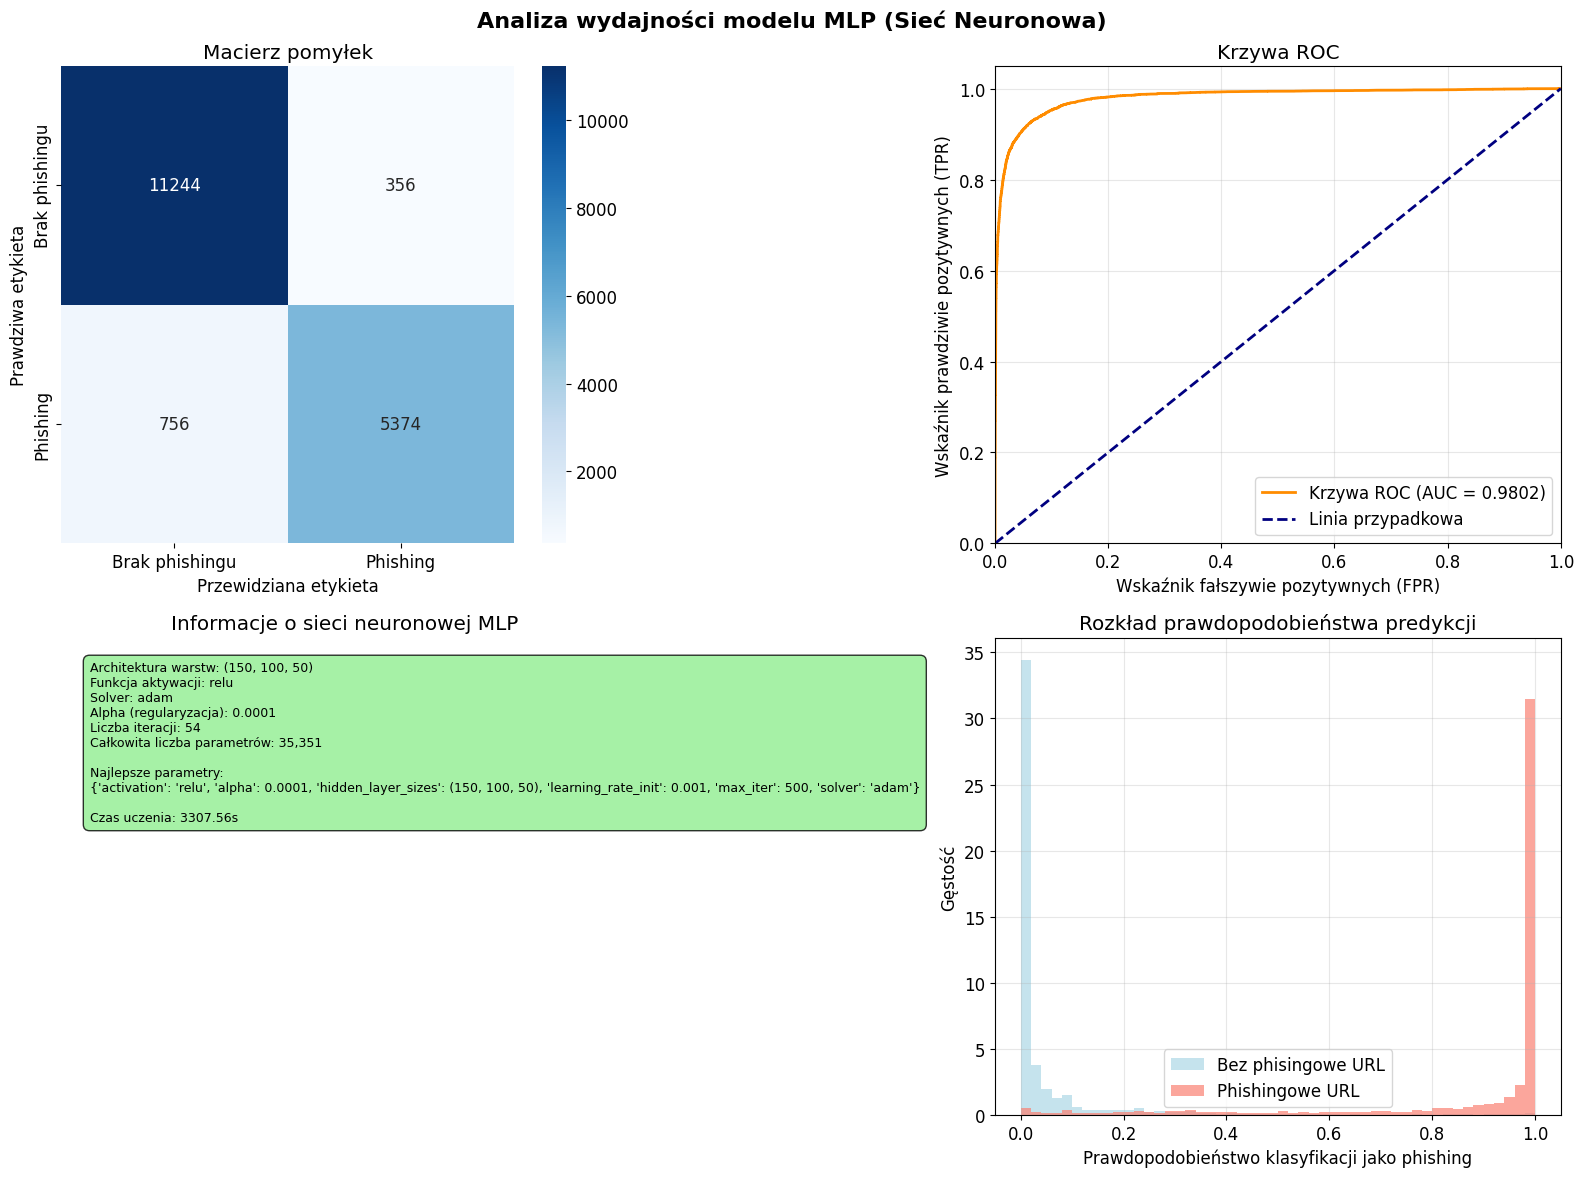


Wydajność modelu: BARDZO DOBRA

🔧 Złożoność modelu: ŚREDNIA (35,351 parametrów)


In [6]:

y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_pred_proba)

print("Przeprowadzanie walidacji krzyżowej...")
cv_scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5, scoring='roc_auc')

print("\n" + "="*50)
print("="*50)
print(f"Dokładność:     {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precyzja:       {precision:.4f} ({precision*100:.2f}%)")
print(f"Czułość:        {recall:.4f} ({recall*100:.2f}%)")
print(f"Miara F1:       {f1:.4f}")
print(f"ROC-AUC:        {auc_roc:.4f}")
print(f"CV ROC-AUC:     {cv_scores.mean():.4f} (±{cv_scores.std()*2:.4f})")

target_names = ['Bez phisingowe URL', 'Phishingowe URL']
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"\nAnaliza macierzy pomyłek:")
print(f"  Prawdziwie negatywne (TN): {tn:,}")
print(f"  Fałszywie pozytywne (FP): {fp:,}")
print(f"  Fałszywie negatywne (FN): {fn:,}")
print(f"  Prawdziwie pozytywne (TP): {tp:,}")

layers = best_model.hidden_layer_sizes
total_params = 0
prev_size = X_train_scaled.shape[1]

for layer_size in layers:
    total_params += prev_size * layer_size + layer_size
    prev_size = layer_size
total_params += prev_size * 1 + 1  

print(f"\nInformacje o sieci neuronowej:")
print(f"  Architektura warstw: {layers}")
print(f"  Funkcja aktywacji: {best_model.activation}")
print(f"  Solver: {best_model.solver}")
print(f"  Alpha (regularyzacja): {best_model.alpha}")
print(f"  Liczba iteracji: {best_model.n_iter_}")
print(f"  Całkowita liczba parametrów: {total_params:,}")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Analiza wydajności modelu MLP (Sieć Neuronowa)', fontsize=16, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Brak phishingu', 'Phishing'], 
            yticklabels=['Brak phishingu', 'Phishing'], 
            ax=axes[0,0])
axes[0,0].set_title('Macierz pomyłek')
axes[0,0].set_ylabel('Prawdziwa etykieta')
axes[0,0].set_xlabel('Przewidziana etykieta')

fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[0,1].plot(fpr, tpr, color='darkorange', lw=2, 
               label=f'Krzywa ROC (AUC = {auc_roc:.4f})')
axes[0,1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', 
               label='Linia przypadkowa')
axes[0,1].set_xlim([0.0, 1.0])
axes[0,1].set_ylim([0.0, 1.05])
axes[0,1].set_xlabel('Wskaźnik fałszywie pozytywnych (FPR)')
axes[0,1].set_ylabel('Wskaźnik prawdziwie pozytywnych (TPR)')
axes[0,1].set_title('Krzywa ROC')
axes[0,1].legend(loc="lower right")
axes[0,1].grid(True, alpha=0.3)

mlp_info = f'''Architektura warstw: {best_model.hidden_layer_sizes}
Funkcja aktywacji: {best_model.activation}
Solver: {best_model.solver}
Alpha (regularyzacja): {best_model.alpha}
Liczba iteracji: {best_model.n_iter_}
Całkowita liczba parametrów: {total_params:,}

Najlepsze parametry:
{best_overall_params}

Czas uczenia: {total_time:.2f}s'''

axes[1,0].text(0.05, 0.95, mlp_info, ha='left', va='top', fontsize=9,
               bbox=dict(boxstyle='round,pad=0.5', facecolor='lightgreen', alpha=0.8),
               transform=axes[1,0].transAxes)
axes[1,0].set_title('Informacje o sieci neuronowej MLP')
axes[1,0].set_xlim(0, 1)
axes[1,0].set_ylim(0, 1)
axes[1,0].axis('off')

axes[1,1].hist(y_pred_proba[y_test == 0], bins=50, alpha=0.7, 
               label='Bez phisingowe URL', color='lightblue', density=True)
axes[1,1].hist(y_pred_proba[y_test == 1], bins=50, alpha=0.7, 
               label='Phishingowe URL', color='salmon', density=True)
axes[1,1].set_xlabel('Prawdopodobieństwo klasyfikacji jako phishing')
axes[1,1].set_ylabel('Gęstość')
axes[1,1].set_title('Rozkład prawdopodobieństwa predykcji')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()

plot_filename = f"{PLOTS_DIR}/mlp_analysis.png"
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')

plt.show()

print(f"\n{'='*50}")
print(f"{'='*50}")

high_performance_metrics = [
    accuracy >= 0.95, 
    precision >= 0.95, 
    recall >= 0.95, 
    f1 >= 0.95, 
    auc_roc >= 0.95
]

if all(high_performance_metrics):
    performance_level = "DOSKONAŁA"
elif accuracy >= 0.90 and auc_roc >= 0.90:
    performance_level = "BARDZO DOBRA"
elif accuracy >= 0.85 and auc_roc >= 0.85:
    performance_level = "DOBRA"
else:
    performance_level = "WYMAGA POPRAWY"

print(f"Wydajność modelu: {performance_level}")

complexity_level = "NISKA" if total_params < 10000 else "ŚREDNIA" if total_params < 50000 else "WYSOKA"
print(f"\n🔧 Złożoność modelu: {complexity_level} ({total_params:,} parametrów)")

In [7]:

import pickle
import os

os.makedirs('../models', exist_ok=True)
os.makedirs('../data', exist_ok=True)

model_data = {
    'model': best_model,
    'scaler': scaler, 
    'feature_names': X.columns.tolist(),
    'best_params': best_overall_params,
    'metrics': {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc,
        'cv_auc_mean': cv_scores.mean(),
        'cv_auc_std': cv_scores.std(),
        'n_iter': best_model.n_iter_,
        'hidden_layers': best_model.hidden_layer_sizes,
        'total_parameters': total_params
    }
}

model_path = '../models/mlp_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_data, f)

results_df = pd.DataFrame({
    'Metryka': ['Dokładność', 'Precyzja', 'Czułość', 'Miara F1', 'AUC-ROC'],
    'Wartość': [accuracy, precision, recall, f1, auc_roc]
})

results_path = '../data/mlp_results.csv'
results_df.to_csv(results_path, index=False)

performance_summary = {
    'typ_modelu': 'MLP (Sieć Neuronowa)',
    'architektura': str(best_model.hidden_layer_sizes),
    'funkcja_aktywacji': best_model.activation,
    'solver': best_model.solver,
    'dokładność': accuracy,
    'precyzja': precision,
    'czułość': recall,
    'miara_f1': f1,
    'roc_auc': auc_roc,
    'cv_auc_średnia': cv_scores.mean(),
    'cv_auc_odchylenie': cv_scores.std(),
    'liczba_cech': len(X.columns),
    'próbki_uczące': len(X_train_scaled),
    'próbki_testowe': len(X_test_scaled),
    'czas_strojenia': total_time,
    'najlepsza_konfiguracja': best_config_name,
    'liczba_parametrów': total_params,
    'liczba_iteracji': best_model.n_iter_
}

print(f"\n{'='*50}")
print(f"{'='*50}")
for key, value in performance_summary.items():
    if isinstance(value, float):
        print(f"{key.replace('_', ' ').title()}: {value:.4f}")
    else:
        print(f"{key.replace('_', ' ').title()}: {value}")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Brak phishingu', 'Phishing'], 
            yticklabels=['Brak phishingu', 'Phishing'])
plt.title('Macierz pomyłek - MLP')
plt.ylabel('Prawdziwa etykieta')
plt.xlabel('Przewidziana etykieta')
plt.savefig(f'{PLOTS_DIR}/mlp_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Krzywa ROC (AUC = {auc_roc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Wskaźnik fałszywie pozytywnych')
plt.ylabel('Wskaźnik prawdziwie pozytywnych')
plt.title('Krzywa ROC - MLP')
plt.legend(loc="lower right")
plt.savefig(f'{PLOTS_DIR}/mlp_roc_curve.png', dpi=300, bbox_inches='tight')
plt.close()


Typ Modelu: MLP (Sieć Neuronowa)
Architektura: (150, 100, 50)
Funkcja Aktywacji: relu
Solver: adam
Dokładność: 0.9373
Precyzja: 0.9379
Czułość: 0.8767
Miara F1: 0.9062
Roc Auc: 0.9802
Cv Auc Średnia: 0.9809
Cv Auc Odchylenie: 0.0011
Liczba Cech: 100
Próbki Uczące: 70917
Próbki Testowe: 17730
Czas Strojenia: 3307.5587
Najlepsza Konfiguracja: Zaawansowane sieci
Liczba Parametrów: 35351
Liczba Iteracji: 54
